Размер данных: (891, 12)

Используем 7 признаков: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']

Обучающая выборка: 713 пассажиров
Тестовая выборка: 178 пассажиров

Обучение моделей

1. Базовая модель
  Эпоха 0: loss=0.6934
  Эпоха 400: loss=0.6690
  Эпоха 800: loss=0.7217
  Эпоха 1200: loss=0.8242
  Эпоха 1600: loss=0.8818
  Точность: обучение=80.2%, тест=79.2%

2. Модель с L2 регуляризацией
  Точность: обучение=80.2%, тест=79.2%

3. Модель с ранней остановкой
  Ранняя остановка на эпохе 610
  Точность: обучение=75.7%, тест=77.5%

4. Ансамбль моделей
  Модель 1: 79.2%
  Модель 2: 79.2%
  Модель 3: 79.2%
  Модель 4: 79.2%
  Модель 5: 79.2%
  Модель 6: 79.2%
  Модель 7: 79.2%
  Точность ансамбля: 79.2%

Визуализация результатов


/tmp/ipython-input-3419961369.py:273: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(model_names, rotation=45, ha='right')


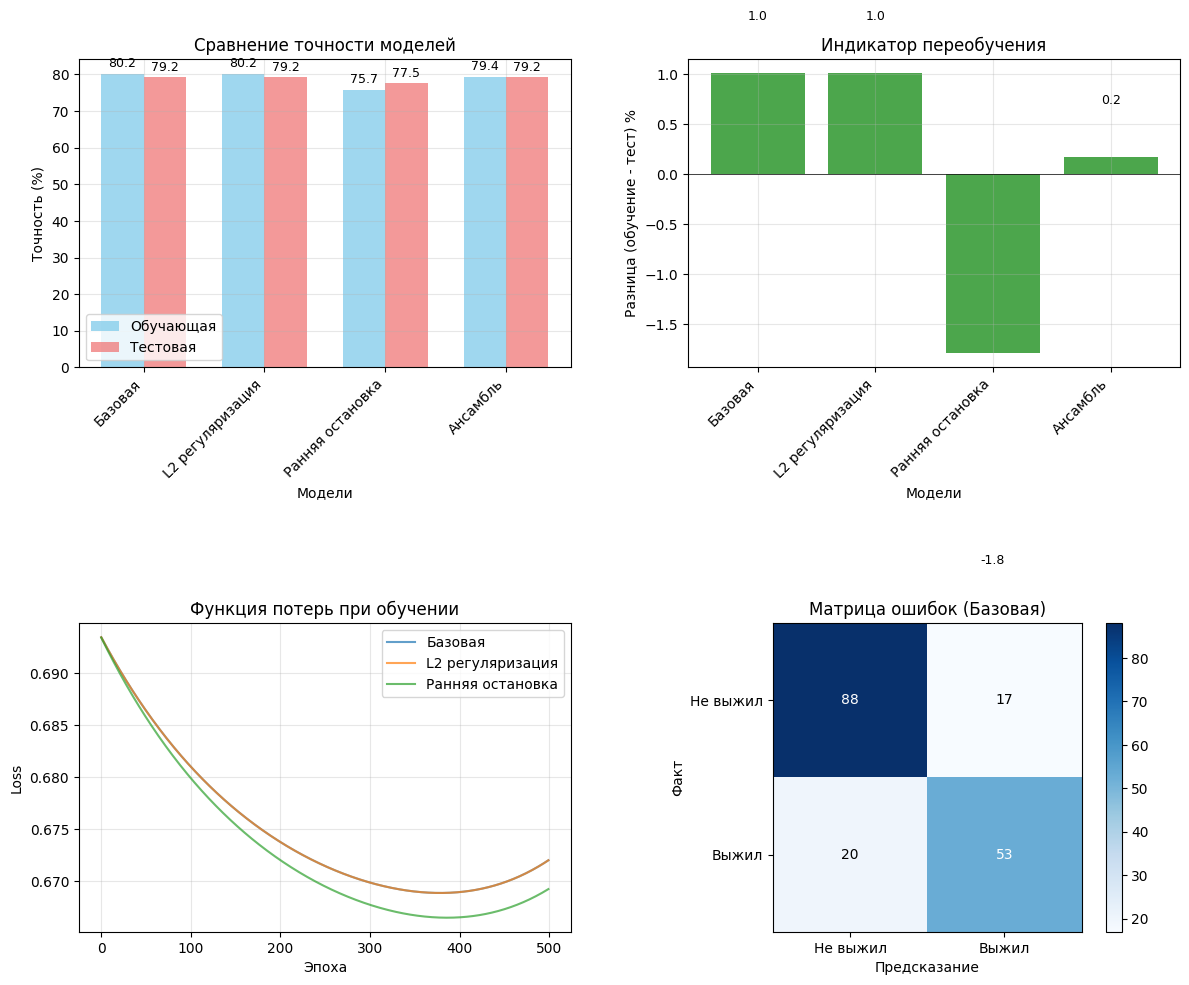


Итоговые результаты:
           Метод  Обучающая (%)  Тестовая (%)   Разница Переобучение
         Базовая      80.224404     79.213483  1.010921          Нет
L2 регуляризация      80.224404     79.213483  1.010921          Нет
Ранняя остановка      75.736325     77.528090 -1.791765          Нет
        Ансамбль      79.382889     79.213483  0.169406          Нет

Лучший результат: 79.2% (Базовая)


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Загружаем данные
url = 'https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv'
data = pd.read_csv(url)

print("Размер данных:", data.shape)

# 1. Предобработка данных
data = data.copy()
data['Age'] = data['Age'].fillna(data['Age'].median())
data['Embarked'] = data['Embarked'].fillna('S')
data['Fare'] = data['Fare'].fillna(data['Fare'].median())

data['Sex'] = data['Sex'].map({'female': 0, 'male': 1})
data['Embarked'] = data['Embarked'].map({'S': 0, 'C': 1, 'Q': 2})

features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
X = data[features].values
y = data['Survived'].values

print(f"\nИспользуем {len(features)} признаков: {features}")

# 2. Разделение данных
def train_test_split_simple(X, y, test_size=0.2, random_state=42):
    np.random.seed(random_state)
    n_samples = X.shape[0]
    n_test = int(n_samples * test_size)
    indices = np.arange(n_samples)
    np.random.shuffle(indices)
    test_indices = indices[:n_test]
    train_indices = indices[n_test:]
    return X[train_indices], X[test_indices], y[train_indices], y[test_indices]

# 3. Нормализация
def normalize_data(X_train, X_test):
    mean = X_train.mean(axis=0)
    std = X_train.std(axis=0)
    std[std == 0] = 1
    X_train_norm = (X_train - mean) / std
    X_test_norm = (X_test - mean) / std
    return X_train_norm, X_test_norm

# Разделяем данные
X_train, X_test, y_train, y_test = train_test_split_simple(X, y, test_size=0.2)
X_train_norm, X_test_norm = normalize_data(X_train, X_test)

print(f"\nОбучающая выборка: {X_train.shape[0]} пассажиров")
print(f"Тестовая выборка: {X_test.shape[0]} пассажиров")

# 4. Нейронная сеть
class SimpleNet:
    def __init__(self, input_size, hidden_size=8, learning_rate=0.01):
        np.random.seed(42)
        self.W1 = np.random.randn(input_size, hidden_size) * 0.1
        self.b1 = np.zeros((1, hidden_size))
        self.W2 = np.random.randn(hidden_size, 1) * 0.1
        self.b2 = np.zeros((1, 1))
        self.lr = learning_rate
        self.loss_history = []

    def sigmoid(self, x):
        return 1 / (1 + np.exp(-x))

    def forward(self, X):
        self.z1 = X.dot(self.W1) + self.b1
        self.a1 = np.tanh(self.z1)
        self.z2 = self.a1.dot(self.W2) + self.b2
        self.a2 = self.sigmoid(self.z2)
        return self.a2

    def compute_loss(self, y_true, y_pred):
        m = y_true.shape[0]
        loss = -np.mean(y_true * np.log(y_pred + 1e-8) + (1 - y_true) * np.log(1 - y_pred + 1e-8))
        return loss

    def backward(self, X, y_true, y_pred):
        m = X.shape[0]
        dz2 = y_pred - y_true.reshape(-1, 1)
        dW2 = (1/m) * self.a1.T.dot(dz2)
        db2 = (1/m) * np.sum(dz2, axis=0, keepdims=True)
        da1 = dz2.dot(self.W2.T)
        dz1 = da1 * (1 - self.a1**2)
        dW1 = (1/m) * X.T.dot(dz1)
        db1 = (1/m) * np.sum(dz1, axis=0, keepdims=True)
        self.W2 -= self.lr * dW2
        self.b2 -= self.lr * db2
        self.W1 -= self.lr * dW1
        self.b1 -= self.lr * db1

    def predict(self, X):
        y_pred = self.forward(X)
        return (y_pred > 0.5).astype(int)

    def accuracy(self, X, y_true):
        y_pred = self.predict(X)
        return np.mean(y_pred.flatten() == y_true) * 100

# 5. Обучение моделей
print("\n" + "="*50)
print("Обучение моделей")

input_size = X_train_norm.shape[1]
results = []
all_losses = []

# Модель 1: Базовая
print("\n1. Базовая модель")
model1 = SimpleNet(input_size, hidden_size=8, learning_rate=0.01)
loss_history1 = []

for epoch in range(2000):
    y_pred = model1.forward(X_train_norm)
    loss = model1.compute_loss(y_train, y_pred)
    loss_history1.append(loss)
    model1.backward(X_train_norm, y_train, y_pred)
    if epoch % 400 == 0:
        print(f"  Эпоха {epoch}: loss={loss:.4f}")

train_acc1 = model1.accuracy(X_train_norm, y_train)
test_acc1 = model1.accuracy(X_test_norm, y_test)
results.append(("Базовая", train_acc1, test_acc1))Ы
all_losses.append(loss_history1)
print(f"  Точность: обучение={train_acc1:.1f}%, тест={test_acc1:.1f}%")

# Модель 2: С регуляризацией
print("\n2. Модель с L2 регуляризацией")

class RegularizedNet(SimpleNet):
    def backward(self, X, y_true, y_pred):
        m = X.shape[0]
        lambda_reg = 0.01

        dz2 = y_pred - y_true.reshape(-1, 1)
        dW2 = (1/m) * self.a1.T.dot(dz2) + (lambda_reg/m) * self.W2
        db2 = (1/m) * np.sum(dz2, axis=0, keepdims=True)
        da1 = dz2.dot(self.W2.T)
        dz1 = da1 * (1 - self.a1**2)
        dW1 = (1/m) * X.T.dot(dz1) + (lambda_reg/m) * self.W1
        db1 = (1/m) * np.sum(dz1, axis=0, keepdims=True)

        self.W2 -= self.lr * dW2
        self.b2 -= self.lr * db2
        self.W1 -= self.lr * dW1
        self.b1 -= self.lr * db1

model2 = RegularizedNet(input_size, hidden_size=8, learning_rate=0.01)
loss_history2 = []

for epoch in range(2000):
    y_pred = model2.forward(X_train_norm)
    loss = model2.compute_loss(y_train, y_pred)
    loss_history2.append(loss)
    model2.backward(X_train_norm, y_train, y_pred)

train_acc2 = model2.accuracy(X_train_norm, y_train)
test_acc2 = model2.accuracy(X_test_norm, y_test)
results.append(("L2 регуляризация", train_acc2, test_acc2))
all_losses.append(loss_history2)
print(f"  Точность: обучение={train_acc2:.1f}%, тест={test_acc2:.1f}%")

# Модель 3: С ранней остановкой
print("\n3. Модель с ранней остановкой")
model3 = SimpleNet(input_size, hidden_size=8, learning_rate=0.01)
loss_history3 = []

val_size = 100
X_val = X_train_norm[:val_size]
y_val = y_train[:val_size]
X_train_small = X_train_norm[val_size:]
y_train_small = y_train[val_size:]

best_val_loss = float('inf')
patience = 30
no_improve = 0
best_epoch = 0

for epoch in range(2000):
    y_pred = model3.forward(X_train_small)
    loss = model3.compute_loss(y_train_small, y_pred)
    loss_history3.append(loss)
    model3.backward(X_train_small, y_train_small, y_pred)

    if epoch % 10 == 0:
        val_pred = model3.forward(X_val)
        val_loss = model3.compute_loss(y_val, val_pred)
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            no_improve = 0
            best_epoch = epoch
        else:
            no_improve += 1

        if no_improve >= patience:
            print(f"  Ранняя остановка на эпохе {epoch}")
            break

train_acc3 = model3.accuracy(X_train_norm, y_train)
test_acc3 = model3.accuracy(X_test_norm, y_test)
results.append(("Ранняя остановка", train_acc3, test_acc3))
all_losses.append(loss_history3)
print(f"  Точность: обучение={train_acc3:.1f}%, тест={test_acc3:.1f}%")

# Модель 4: Ансамбль
print("\n4. Ансамбль моделей")
n_models = 7
predictions = []

for i in range(n_models):
    model = SimpleNet(input_size,
                     hidden_size=np.random.choice([6, 7, 8]),
                     learning_rate=0.01)

    for epoch in range(1000):
        y_pred = model.forward(X_train_norm)
        model.backward(X_train_norm, y_train, y_pred)

    pred = model.predict(X_test_norm).flatten()
    predictions.append(pred)
    acc = np.mean(pred == y_test) * 100
    print(f"  Модель {i+1}: {acc:.1f}%")

predictions = np.array(predictions)
ensemble_pred = (predictions.mean(axis=0) > 0.5).astype(int)
ensemble_acc = np.mean(ensemble_pred == y_test) * 100
train_acc_ensemble = model.accuracy(X_train_norm, y_train)

results.append(("Ансамбль", train_acc_ensemble, ensemble_acc))
print(f"  Точность ансамбля: {ensemble_acc:.1f}%")

# 6. ГРАФИКИ
print("\n" + "="*50)
print("Визуализация результатов")

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# График 1: Сравнение точности
ax1 = axes[0, 0]
model_names = [r[0] for r in results]
train_accs = [r[1] for r in results]
test_accs = [r[2] for r in results]

x = np.arange(len(model_names))
width = 0.35

bars1 = ax1.bar(x - width/2, train_accs, width, label='Обучающая', color='skyblue', alpha=0.8)
bars2 = ax1.bar(x + width/2, test_accs, width, label='Тестовая', color='lightcoral', alpha=0.8)

ax1.set_xlabel('Модели')
ax1.set_ylabel('Точность (%)')
ax1.set_title('Сравнение точности моделей')
ax1.set_xticks(x)
ax1.set_xticklabels(model_names, rotation=45, ha='right')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Добавляем значения на столбцы
for i, (train, test) in enumerate(zip(train_accs, test_accs)):
    ax1.text(i - width/2, train + 1, f'{train:.1f}', ha='center', va='bottom', fontsize=9)
    ax1.text(i + width/2, test + 1, f'{test:.1f}', ha='center', va='bottom', fontsize=9)

# График 2: Переобучение
ax2 = axes[0, 1]
overfit_gaps = [train - test for train, test in zip(train_accs, test_accs)]
colors = ['red' if gap > 15 else 'orange' if gap > 5 else 'green' for gap in overfit_gaps]
bars = ax2.bar(model_names, overfit_gaps, color=colors, alpha=0.7)

ax2.set_xlabel('Модели')
ax2.set_ylabel('Разница (обучение - тест) %')
ax2.set_title('Индикатор переобучения')
ax2.set_xticklabels(model_names, rotation=45, ha='right')
ax2.axhline(y=0, color='black', linestyle='-', linewidth=0.5)
ax2.grid(True, alpha=0.3)

# Добавляем значения
for i, gap in enumerate(overfit_gaps):
    ax2.text(i, gap + (0.5 if gap >= 0 else -2), f'{gap:.1f}', ha='center', va='bottom' if gap >= 0 else 'top', fontsize=9)

# График 3: Функции потерь
ax3 = axes[1, 0]
for i, (loss_history, name) in enumerate(zip(all_losses[:3], ['Базовая', 'L2 регуляризация', 'Ранняя остановка'])):
    ax3.plot(loss_history[:500], label=name, alpha=0.7)

ax3.set_xlabel('Эпоха')
ax3.set_ylabel('Loss')
ax3.set_title('Функция потерь при обучении')
ax3.legend()
ax3.grid(True, alpha=0.3)

# График 4: Матрица ошибок для лучшей модели
ax4 = axes[1, 1]
best_idx = np.argmax([r[2] for r in results])
best_model_name = model_names[best_idx]

if best_model_name == "Ансамбль":
    y_pred_best = ensemble_pred
else:
    models_best = [model1, model2, model3]
    y_pred_best = models_best[best_idx].predict(X_test_norm).flatten()

# Создаем матрицу ошибок вручную
tp = np.sum((y_pred_best == 1) & (y_test == 1))
fp = np.sum((y_pred_best == 1) & (y_test == 0))
fn = np.sum((y_pred_best == 0) & (y_test == 1))
tn = np.sum((y_pred_best == 0) & (y_test == 0))

cm = np.array([[tn, fp], [fn, tp]])

# Рисуем матрицу ошибок
im = ax4.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
ax4.set_title(f'Матрица ошибок ({best_model_name})')
plt.colorbar(im, ax=ax4)

thresh = cm.max() / 2
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax4.text(j, i, format(cm[i, j], 'd'),
                ha="center", va="center",
                color="white" if cm[i, j] > thresh else "black")

ax4.set_xticks([0, 1])
ax4.set_yticks([0, 1])
ax4.set_xticklabels(['Не выжил', 'Выжил'])
ax4.set_yticklabels(['Не выжил', 'Выжил'])
ax4.set_ylabel('Факт')
ax4.set_xlabel('Предсказание')

plt.tight_layout()
plt.savefig('titanic_results.png', dpi=100, bbox_inches='tight')
plt.show()

# 7. Результаты
print("\n" + "="*50)
print("Итоговые результаты:")

results_df = pd.DataFrame(results, columns=['Метод', 'Обучающая (%)', 'Тестовая (%)'])
results_df['Разница'] = results_df['Обучающая (%)'] - results_df['Тестовая (%)']
results_df['Переобучение'] = results_df['Разница'].apply(lambda x: 'Да' if x > 15 else 'Нет')

print(results_df.to_string(index=False))

best_idx = np.argmax([r[2] for r in results])
best_method, best_train, best_test = results[best_idx]

print(f"\nЛучший результат: {best_test:.1f}% ({best_method})")